In [3]:
import numpy as np
import pandas as pd 
from matplotlib import pyplot as plt

In [4]:
training = np.loadtxt('trainingI.dat')
validation = np.loadtxt('validationI.dat')
ranges = np.loadtxt('rangesII.dat')
checkpoints = np.loadtxt('checkpointsII.dat')
anchors = np.loadtxt('anchorsII.dat')

In [5]:
def legendre(x, n):
    P = np.zeros(n)

    P[0] = 1
    P[1] = x

    for k in range(1, n-1):
        P[k+1] = ((2*k+1)*x*P[k] - k*P[k-1])/(k+1)

    return P

In [6]:
x = training[:, 0]
b = training[:, 1]

n = 8
m = 60

A = np.zeros((m, n))

for i in range(m):
    A[i, :] = legendre(x[i], n)

In [7]:
theta_ls = np.linalg.inv(A.T @ A) @ A.T @ b


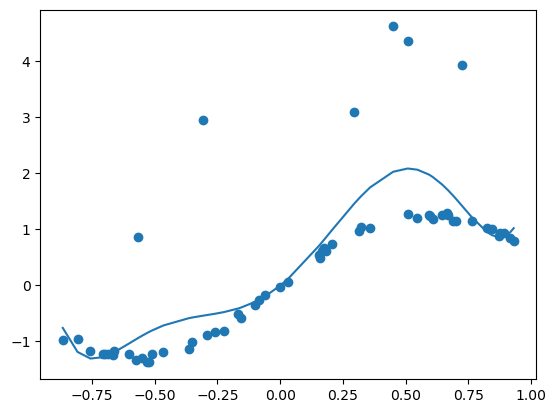

In [8]:
plt.scatter(x, b)
plt.plot(x, A@theta_ls)

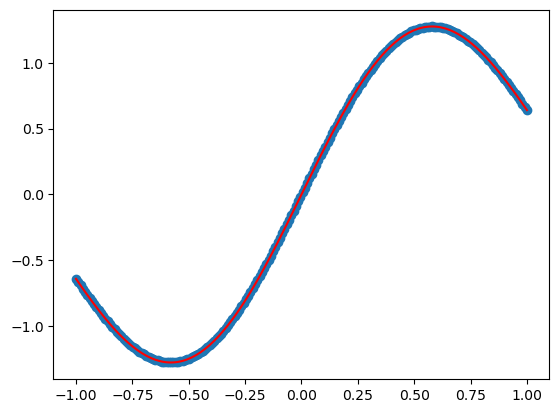

In [9]:
x2, b2 = validation[:, 0], validation[:, 1]
A2 = np.zeros((200,8))
for i in range(200):
    A2[i, :] = legendre(x2[i], n)
    
theta_2 = np.linalg.inv(A2.T @ A2) @ A2.T @ b2
plt.plot(x2, A2@theta_2, color = 'red')
plt.scatter(x2, b2)

In [10]:
validation_error = 0
V = A2 @ theta_2
for i in range(200):
    validation_error += (abs(V[i] - b2[i]))**2

validation_error = validation_error / 200
validation_error

np.float64(1.2063231359239371e-08)

In [11]:
residuals = A2 @ theta_2 - b2
residuals_outliers = A @ theta_ls - b

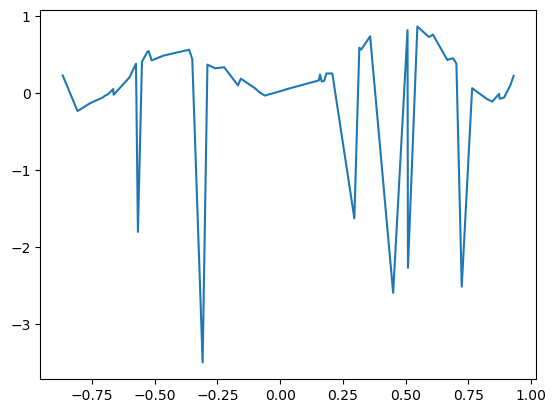

In [12]:
plt.plot(x , residuals_outliers)

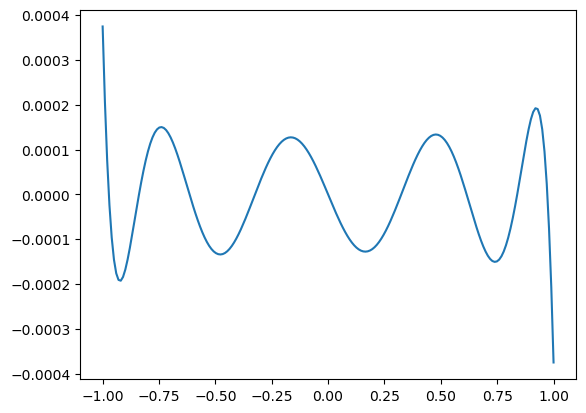

In [13]:
plt.plot(x2, residuals)

In [14]:
np.linalg.cond(A2.T@A2)

np.float64(14.210429548748612)

In [15]:
def polynomial(x, n):
    P = np.zeros(n)
    P[0] = 1
    for i in range(1, n):
        P[i] = x**i
    return P
    
        
        
        

In [16]:
A3 = np.zeros((200, 8))
for i in range(200):
    A3[i : ,] = polynomial(x2[i], n)

np.linalg.cond(A3.T@A3)

np.float64(52902.529947814524)